<a href="https://colab.research.google.com/github/Meenakshi-N-24/RedFlag/blob/main/notebooks/02_distilbert_finetune.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch, pandas as pd

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("val.csv")
indian = pd.read_csv("indian_test_set.csv")

print(len(train_df), len(val_df), len(indian))
print(train_df.columns.tolist())

GPU available: True
Tesla T4
3618 775 100
['label', 'text', 'length', 'y', 'clean']


In [2]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset

MODEL = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL)

class SMSData(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding=True, max_length=128)
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

train_ds = SMSData(train_df["text"], train_df["y"])
val_ds = SMSData(val_df["text"], val_df["y"])
ind_ds = SMSData(indian["text"], indian["label"])
print(len(train_ds), len(val_ds), len(ind_ds))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

3618 775 100


In [3]:
import numpy as np
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    pr, rc, f1, _ = precision_recall_fscore_support(
        p.label_ids, preds, average="binary", pos_label=1, zero_division=0)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "precision": pr, "recall": rc, "f1": f1}

args = TrainingArguments(
    output_dir="distilbert_out",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    fp16=True,
    seed=42,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds,
                  eval_dataset=val_ds, compute_metrics=compute_metrics)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.083369,0.058199,0.989677,0.989130,0.928571,0.957895
2,0.039777,0.051090,0.989677,0.989130,0.928571,0.957895
3,0.007512,0.053340,0.988387,0.978495,0.928571,0.952880


TrainOutput(global_step=681, training_loss=0.04906832725466086, metrics={'train_runtime': 40.753, 'train_samples_per_second': 266.336, 'train_steps_per_second': 16.71, 'total_flos': 359450286253056.0, 'train_loss': 0.04906832725466086, 'epoch': 3.0})

              precision    recall  f1-score   support

       legit      0.286     0.080     0.125        50
        spam      0.465     0.800     0.588        50

    accuracy                          0.440       100
   macro avg      0.375     0.440     0.357       100
weighted avg      0.375     0.440     0.357       100



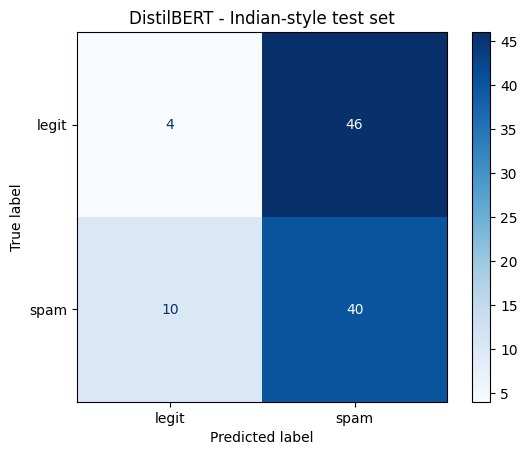

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

out = trainer.predict(ind_ds)
ind_pred = np.argmax(out.predictions, axis=1)

print(classification_report(indian["label"], ind_pred, target_names=["legit", "spam"], digits=3))
cm = confusion_matrix(indian["label"], ind_pred)
ConfusionMatrixDisplay(cm, display_labels=["legit", "spam"]).plot(cmap="Blues")
plt.title("DistilBERT - Indian-style test set"); plt.show()